In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)

C:\Users\Ushas\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 2.29G/2.29G [08:44<00:00, 4.70MB/s] 

Extracting files...


Path to dataset files: C:\Users\Ushas\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2


In [2]:
# ============================================================
# STEP 1: DATASET COLLECTION AND PATH VERIFICATION
# Purpose:
# Verify that the Chest X-Ray Pneumonia dataset has been
# downloaded correctly and inspect the main folder structure.
# ============================================================

import os
import kagglehub

# Download the dataset from KaggleHub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

# Display dataset path
print("Dataset downloaded successfully.")
print("Dataset path:", path)

# Display main files/folders inside the downloaded dataset
print("\nMain folders/files inside dataset:")
print(os.listdir(path))

Dataset downloaded successfully.
Dataset path: C:\Users\Ushas\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2

Main folders/files inside dataset:
['chest_xray']


In [3]:
# ============================================================
# STEP 2: DATASET DIRECTORY IDENTIFICATION
# Purpose:
# Locate the actual image dataset folder and confirm whether
# train, test, and validation directories are available.
# ============================================================

import os

# Main image dataset directory
dataset_dir = os.path.join(path, "chest_xray")

# Print final dataset directory
print("Final dataset directory:")
print(dataset_dir)

# Check available folders inside the dataset directory
print("\nFolders inside chest_xray directory:")
print(os.listdir(dataset_dir))

Final dataset directory:
C:\Users\Ushas\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2\chest_xray

Folders inside chest_xray directory:
['chest_xray', 'test', 'train', 'val', '__MACOSX']


In [4]:
# ============================================================
# STEP 3: VERIFY DATASET CLASSES
# Purpose:
# Confirm the binary classification categories:
# 1. NORMAL
# 2. PNEUMONIA
# ============================================================

# Define dataset split directories
train_dir = os.path.join(dataset_dir, "train")
test_dir = os.path.join(dataset_dir, "test")
val_dir = os.path.join(dataset_dir, "val")

# Display available classes in each split
print("Training Classes:")
print(os.listdir(train_dir))

print("\nTesting Classes:")
print(os.listdir(test_dir))

print("\nValidation Classes:")
print(os.listdir(val_dir))

Training Classes:
['NORMAL', 'PNEUMONIA']

Testing Classes:
['NORMAL', 'PNEUMONIA']

Validation Classes:
['NORMAL', 'PNEUMONIA']


In [5]:
# ============================================================
# STEP 4: DATASET OVERVIEW AND IMAGE COUNT ANALYSIS
# Purpose:
# Count the number of NORMAL and PNEUMONIA images in
# training, testing, and validation datasets.
# This supports Section 4.1 Dataset Overview.
# ============================================================

# Function to count images in each class folder
def count_images(directory):
    class_counts = {}

    for class_name in os.listdir(directory):

        class_path = os.path.join(directory, class_name)

        # Count only valid files
        image_count = len([
            file for file in os.listdir(class_path)
            if os.path.isfile(os.path.join(class_path, file))
        ])

        class_counts[class_name] = image_count

    return class_counts


# Count images in all dataset splits
train_counts = count_images(train_dir)
test_counts = count_images(test_dir)
val_counts = count_images(val_dir)

# Display results
print("Training Dataset:")
print(train_counts)

print("\nTesting Dataset:")
print(test_counts)

print("\nValidation Dataset:")
print(val_counts)

# Calculate total images
total_images = (
    sum(train_counts.values()) +
    sum(test_counts.values()) +
    sum(val_counts.values())
)

print("\nTotal Images in Entire Dataset:", total_images)

Training Dataset:
{'NORMAL': 1341, 'PNEUMONIA': 3875}

Testing Dataset:
{'NORMAL': 234, 'PNEUMONIA': 390}

Validation Dataset:
{'NORMAL': 8, 'PNEUMONIA': 8}

Total Images in Entire Dataset: 5856


In [6]:
# ============================================================
# STEP 5: CREATE PROFESSIONAL DATASET SUMMARY TABLE
# Purpose:
# Generate a clean dataset overview table for analysis
# and research paper reporting.
# ============================================================

import pandas as pd

# Create dataset summary table
dataset_summary = pd.DataFrame({

    "Dataset Split": ["Training", "Testing", "Validation"],

    "NORMAL Images": [
        train_counts["NORMAL"],
        test_counts["NORMAL"],
        val_counts["NORMAL"]
    ],

    "PNEUMONIA Images": [
        train_counts["PNEUMONIA"],
        test_counts["PNEUMONIA"],
        val_counts["PNEUMONIA"]
    ]

})

# Add total images column
dataset_summary["Total Images"] = (
    dataset_summary["NORMAL Images"] +
    dataset_summary["PNEUMONIA Images"]
)

# Display summary table
print(dataset_summary)

  Dataset Split  NORMAL Images  PNEUMONIA Images  Total Images
0      Training           1341              3875          5216
1       Testing            234               390           624
2    Validation              8                 8            16


Sample NORMAL Chest X-ray Images


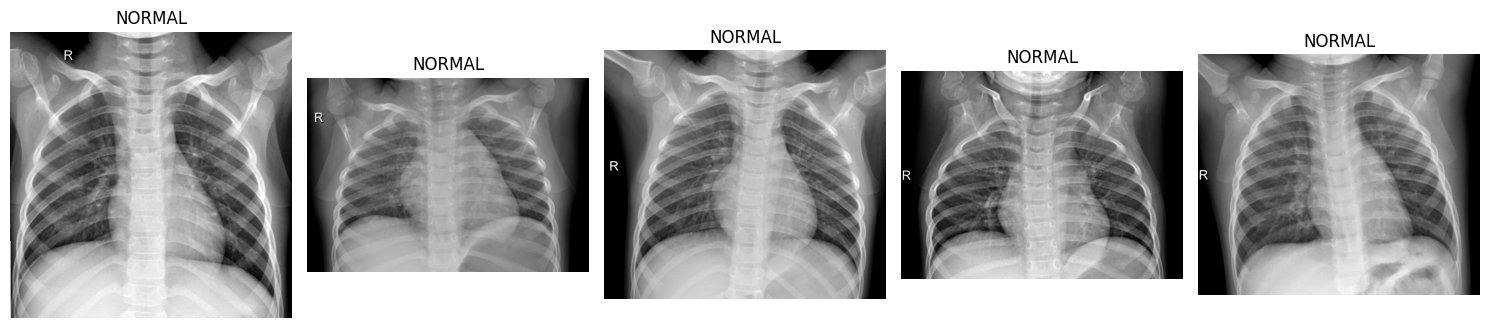

Sample PNEUMONIA Chest X-ray Images


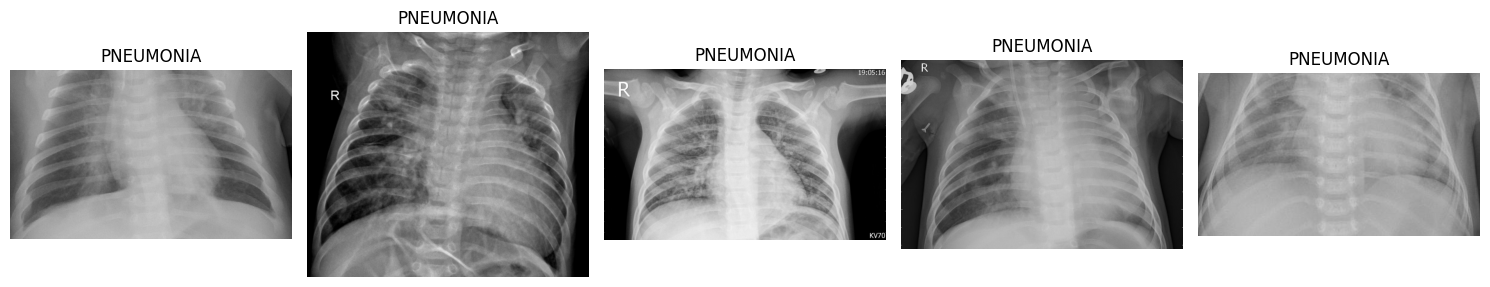

In [7]:
# ============================================================
# STEP 6: VISUALIZE SAMPLE CHEST X-RAY IMAGES
# Purpose:
# Display sample NORMAL and PNEUMONIA chest X-ray images
# before preprocessing and enhancement.
# This supports:
# Figure 3: Sample Preprocessed X-ray Images
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image
import random

# Function to display sample images
def show_sample_images(directory, class_name, num_images=5):

    class_path = os.path.join(directory, class_name)

    # Randomly select images
    image_files = random.sample(os.listdir(class_path), num_images)

    # Create figure
    plt.figure(figsize=(15, 5))

    for i, image_name in enumerate(image_files):

        image_path = os.path.join(class_path, image_name)

        # Open image
        image = Image.open(image_path)

        # Plot image
        plt.subplot(1, num_images, i + 1)
        plt.imshow(image, cmap='gray')
        plt.title(class_name)
        plt.axis("off")

    plt.tight_layout()
    plt.show()


# Display NORMAL images
print("Sample NORMAL Chest X-ray Images")
show_sample_images(train_dir, "NORMAL")

# Display PNEUMONIA images
print("Sample PNEUMONIA Chest X-ray Images")
show_sample_images(train_dir, "PNEUMONIA")

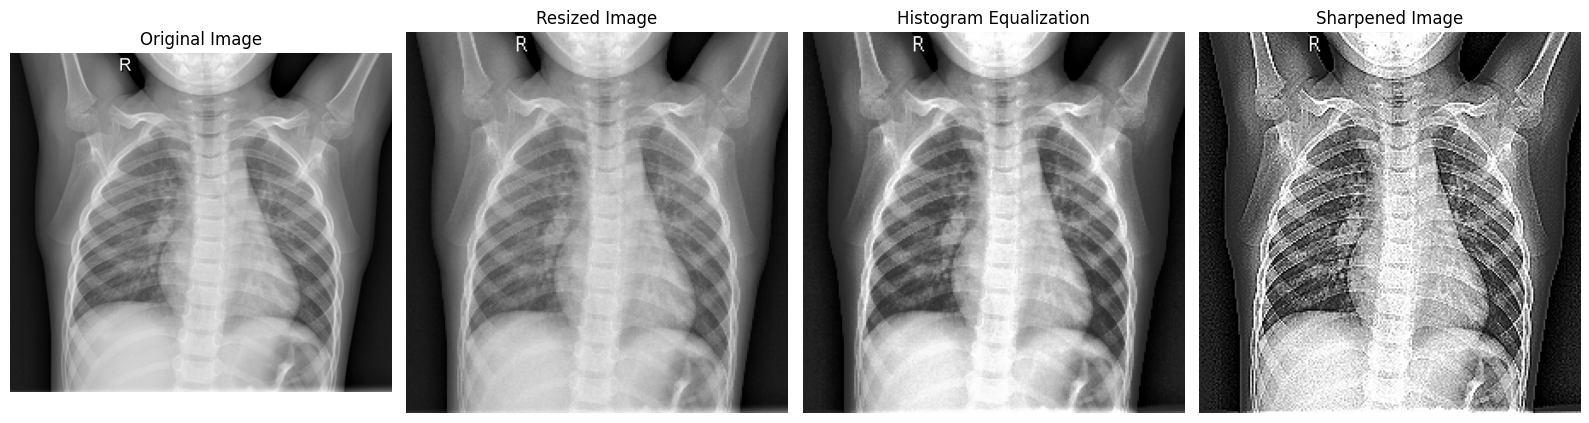

Original Image Shape: (1858, 2090)
Resized Image Shape: (224, 224)

Pixel Value Range After Normalization:
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [8]:
# ============================================================
# STEP 7: IMAGE PREPROCESSING AND ENHANCEMENT
# Purpose:
# Perform professional medical image preprocessing for
# deep learning model development.
#
# Operations:
# 1. Resize images
# 2. Convert to grayscale
# 3. Normalize pixel values
# 4. Contrast enhancement
# 5. Histogram equalization
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Select one sample image from NORMAL class
sample_image_path = os.path.join(
    train_dir,
    "NORMAL",
    os.listdir(os.path.join(train_dir, "NORMAL"))[0]
)

# Read image in grayscale mode
image = cv2.imread(sample_image_path, cv2.IMREAD_GRAYSCALE)

# Resize image
resized_image = cv2.resize(image, (224, 224))

# Normalize image
normalized_image = resized_image / 255.0

# Apply histogram equalization
equalized_image = cv2.equalizeHist(resized_image)

# Apply sharpening filter
kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

sharpened_image = cv2.filter2D(equalized_image, -1, kernel)

# ============================================================
# VISUALIZATION OF PREPROCESSING PIPELINE
# ============================================================

titles = [
    "Original Image",
    "Resized Image",
    "Histogram Equalization",
    "Sharpened Image"
]

images = [
    image,
    resized_image,
    equalized_image,
    sharpened_image
]

plt.figure(figsize=(16, 5))

for i in range(4):

    plt.subplot(1, 4, i + 1)

    plt.imshow(images[i], cmap='gray')

    plt.title(titles[i], fontsize=12)

    plt.axis("off")

plt.tight_layout()
plt.show()

# ============================================================
# DISPLAY IMAGE INFORMATION
# ============================================================

print("Original Image Shape:", image.shape)
print("Resized Image Shape:", resized_image.shape)

print("\nPixel Value Range After Normalization:")
print("Minimum Pixel Value:", normalized_image.min())
print("Maximum Pixel Value:", normalized_image.max())

In [10]:
# ============================================================
# STEP 8: DATA AUGMENTATION AND AI-READY DATA PIPELINE
# Purpose:
# Create training, validation, and testing generators
# for CNN, ResNet50, and VGG16 model development.
#
# Techniques Applied:
# 1. Rescaling
# 2. Rotation
# 3. Zoom augmentation
# 4. Horizontal shifting
# 5. Validation preprocessing
# ============================================================

%pip install tensorflow

from tensorflow.keras.preprocessing.image import ImageDataGenerator

# ============================================================
# IMAGE SIZE AND BATCH CONFIGURATION
# ============================================================

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

# ============================================================
# TRAINING DATA GENERATOR
# ============================================================

train_datagen = ImageDataGenerator(

    # Normalize pixel values
    rescale=1./255,

    # Data augmentation
    rotation_range=15,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,

    # Validation split
    validation_split=0.2
)

# ============================================================
# TESTING DATA GENERATOR
# ============================================================

test_datagen = ImageDataGenerator(rescale=1./255)

# ============================================================
# TRAINING GENERATOR
# ============================================================

train_generator = train_datagen.flow_from_directory(

    train_dir,

    target_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    class_mode='binary',

    subset='training',

    shuffle=True
)

# ============================================================
# VALIDATION GENERATOR
# ============================================================

validation_generator = train_datagen.flow_from_directory(

    train_dir,

    target_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    class_mode='binary',

    subset='validation',

    shuffle=True
)

# ============================================================
# TEST GENERATOR
# ============================================================

test_generator = test_datagen.flow_from_directory(

    test_dir,

    target_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    class_mode='binary',

    shuffle=False
)

# ============================================================
# DISPLAY CLASS INDICES
# ============================================================

print("\nClass Labels:")
print(train_generator.class_indices)

# ============================================================
# DISPLAY DATASET INFORMATION
# ============================================================

print("\nTraining Samples:", train_generator.samples)
print("Validation Samples:", validation_generator.samples)
print("Testing Samples:", test_generator.samples)

Defaulting to user installation because normal site-packages is not writeable
  Using cached wheel-0.47.0-py3-none-any.whl.metadata (2.3 kB)
   ---------------------------------------- 0.0/350.9 MB ? eta -:--:--
   ---------------------------------------- 2.1/350.9 MB 13.1 MB/s eta 0:00:27
   ---------------------------------------- 2.9/350.9 MB 12.9 MB/s eta 0:00:27
   ---------------------------------------- 3.9/350.9 MB 9.0 MB/s eta 0:00:39
    --------------------------------------- 6.3/350.9 MB 7.7 MB/s eta 0:00:45
    --------------------------------------- 7.3/350.9 MB 7.3 MB/s eta 0:00:47
    --------------------------------------- 7.9/350.9 MB 6.7 MB/s eta 0:00:52
    --------------------------------------- 8.1/350.9 MB 6.3 MB/s eta 0:00:55
    --------------------------------------- 8.7/350.9 MB 5.3 MB/s eta 0:01:05
   - -------------------------------------- 8.9/350.9 MB 5.1 MB/s eta 0:01:08
   - -------------------------------------- 9.7/350.9 MB 4.7 MB/s eta 0:01:13
   - -


[notice] A new release of pip is available: 24.2 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Found 4173 images belonging to 2 classes.
Found 1043 images belonging to 2 classes.
Found 624 images belonging to 2 classes.

Class Labels:
{'NORMAL': 0, 'PNEUMONIA': 1}

Training Samples: 4173
Validation Samples: 1043
Testing Samples: 624


In [11]:
# ============================================================
# STEP 9: CNN BASELINE MODEL ARCHITECTURE
# Purpose:
# Develop a baseline Convolutional Neural Network model
# for binary classification of chest X-ray images:
# NORMAL vs PNEUMONIA.
#
# This model will be used as the baseline for comparison with:
# 1. ResNet50
# 2. VGG16
# ============================================================

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam

# ============================================================
# DEFINE CNN MODEL
# ============================================================

cnn_model = Sequential([

    # First convolution block
    Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),

    # Second convolution block
    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),

    # Third convolution block
    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),

    # Fourth convolution block
    Conv2D(256, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),

    # Flatten feature maps
    Flatten(),

    # Fully connected layer
    Dense(256, activation='relu'),
    Dropout(0.5),

    # Output layer for binary classification
    Dense(1, activation='sigmoid')
])

# ============================================================
# COMPILE CNN MODEL
# ============================================================

cnn_model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# ============================================================
# DISPLAY MODEL ARCHITECTURE
# ============================================================

cnn_model.summary()

C:\Users\Ushas\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     9,437,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,828,033 (37.49 MB)

 Trainable params: 9,827,073 (37.49 MB)

 Non-trainable params: 960 (3.75 KB)

In [12]:
# ============================================================
# STEP 10: CNN BASELINE MODEL TRAINING
# Purpose:
# Train the baseline CNN model on augmented chest X-ray images
# for NORMAL vs PNEUMONIA classification.
#
# Training Strategy:
# 1. Use augmented training data
# 2. Validate performance on validation split
# 3. Save best model using validation accuracy
# 4. Stop training early if validation loss does not improve
# ============================================================

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# ============================================================
# DEFINE CALLBACKS
# ============================================================

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    filepath='best_cnn_model.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

# ============================================================
# TRAIN CNN MODEL
# ============================================================

cnn_history = cnn_model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=20,
    callbacks=[early_stop, checkpoint, reduce_lr],
    verbose=1
)

Epoch 1/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8359 - loss: 0.5845
Epoch 1: val_accuracy improved from None to 0.74305, saving model to best_cnn_model.keras

Epoch 1: finished saving model to best_cnn_model.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 447s 3s/step - accuracy: 0.8744 - loss: 0.3801 - val_accuracy: 0.7430 - val_loss: 5.6737 - learning_rate: 1.0000e-04
Epoch 2/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9162 - loss: 0.2174
Epoch 2: val_accuracy did not improve from 0.74305
131/131 ━━━━━━━━━━━━━━━━━━━━ 330s 3s/step - accuracy: 0.9161 - loss: 0.2136 - val_accuracy: 0.7430 - val_loss: 8.8743 - learning_rate: 1.0000e-04
Epoch 3/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9286 - loss: 0.1780
Epoch 3: val_accuracy did not improve from 0.74305
131/131 ━━━━━━━━━━━━━━━━━━━━ 377s 3s/step - accuracy: 0.9293 - loss: 0.1847 - val_accuracy: 0.7430 - val_loss: 6.2659 - learning_rate: 1.0000e-04
Epoch 4/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accura

20/20 ━━━━━━━━━━━━━━━━━━━━ 17s 776ms/step
CNN Test Accuracy: 88.78 %

Classification Report:

              precision    recall  f1-score   support

      NORMAL       0.92      0.77      0.84       234
   PNEUMONIA       0.87      0.96      0.91       390

    accuracy                           0.89       624
   macro avg       0.90      0.86      0.88       624
weighted avg       0.89      0.89      0.89       624



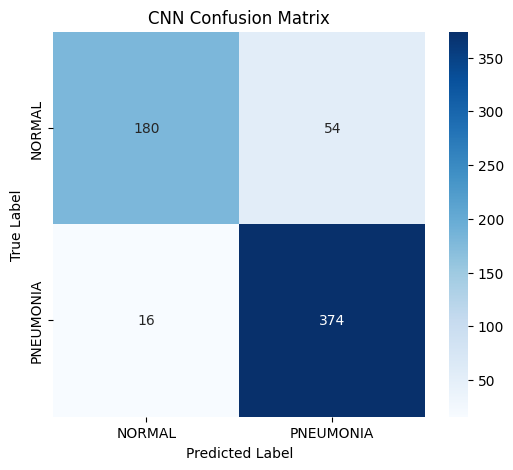

In [13]:
# ============================================================
# STEP 11: CNN MODEL PERFORMANCE EVALUATION
# Purpose:
# Evaluate CNN performance on unseen test dataset using:
#
# 1. Accuracy
# 2. Precision
# 3. Recall
# 4. F1-score
# 5. Confusion Matrix
# ============================================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# GENERATE PREDICTIONS
# ============================================================

predictions = cnn_model.predict(test_generator)

# Convert probabilities into binary labels
predicted_classes = (predictions > 0.5).astype(int).reshape(-1)

# True labels
true_classes = test_generator.classes

# ============================================================
# ACCURACY
# ============================================================

test_accuracy = accuracy_score(true_classes, predicted_classes)

print("CNN Test Accuracy:", round(test_accuracy * 100, 2), "%")

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:\n")

print(classification_report(
    true_classes,
    predicted_classes,
    target_names=["NORMAL", "PNEUMONIA"]
))

# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("CNN Confusion Matrix")

plt.show()

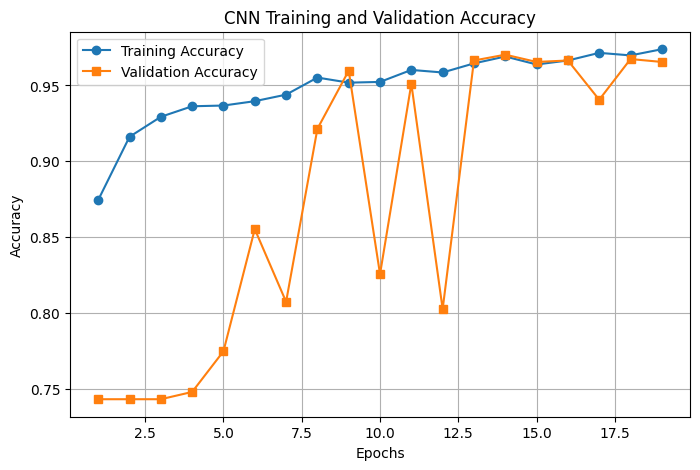

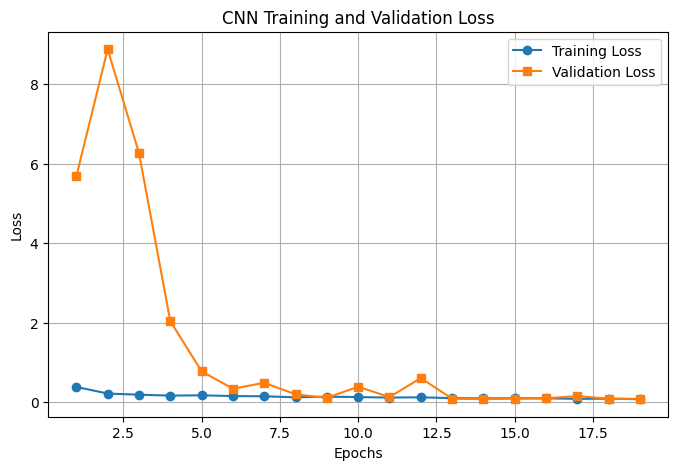

In [14]:
# ============================================================
# STEP 12: CNN TRAINING PERFORMANCE VISUALIZATION
# Purpose:
# Visualize CNN training and validation performance using:
#
# 1. Accuracy vs Epoch
# 2. Loss vs Epoch
#
# These figures will support:
# Figure 5: Model Accuracy Comparison
# ============================================================

import matplotlib.pyplot as plt

# ============================================================
# EXTRACT TRAINING HISTORY
# ============================================================

train_accuracy = cnn_history.history['accuracy']
val_accuracy = cnn_history.history['val_accuracy']

train_loss = cnn_history.history['loss']
val_loss = cnn_history.history['val_loss']

epochs_range = range(1, len(train_accuracy) + 1)

# ============================================================
# ACCURACY PLOT
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_accuracy,
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    epochs_range,
    val_accuracy,
    marker='s',
    label='Validation Accuracy'
)

plt.title("CNN Training and Validation Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.show()

# ============================================================
# LOSS PLOT
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_loss,
    marker='o',
    label='Training Loss'
)

plt.plot(
    epochs_range,
    val_loss,
    marker='s',
    label='Validation Loss'
)

plt.title("CNN Training and Validation Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

In [15]:
# ============================================================
# STEP 13: RESNET50 MODEL DEVELOPMENT
# Purpose:
# Develop an advanced transfer learning model using ResNet50
# for pneumonia detection from chest X-ray images.
#
# Why ResNet50?
# 1. Deep residual learning
# 2. Better feature extraction
# 3. Improved gradient flow
# 4. Strong medical imaging performance
# ============================================================

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

# ============================================================
# LOAD PRETRAINED RESNET50 MODEL
# ============================================================

base_model = ResNet50(

    weights='imagenet',

    include_top=False,

    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# ============================================================
# ADD CUSTOM CLASSIFICATION LAYERS
# ============================================================

x = base_model.output

x = GlobalAveragePooling2D()(x)

x = Dense(256, activation='relu')(x)

x = Dropout(0.5)(x)

output = Dense(1, activation='sigmoid')(x)

# ============================================================
# BUILD FINAL MODEL
# ============================================================

resnet_model = Model(
    inputs=base_model.input,
    outputs=output
)

# ============================================================
# COMPILE MODEL
# ============================================================

resnet_model.compile(

    optimizer=Adam(learning_rate=0.0001),

    loss='binary_crossentropy',

    metrics=['accuracy']
)

# ============================================================
# DISPLAY MODEL SUMMARY
# ============================================================

resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 20s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,112,513 (91.98 MB)

 Trainable params: 524,801 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [16]:
# ============================================================
# STEP 14: RESNET50 MODEL TRAINING
# Purpose:
# Train the advanced ResNet50 transfer learning model
# for pneumonia detection.
#
# Strategy:
# 1. Transfer learning
# 2. Early stopping
# 3. Learning-rate reduction
# 4. Best-model checkpointing
# ============================================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# ============================================================
# CALLBACKS
# ============================================================

early_stop_resnet = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

checkpoint_resnet = ModelCheckpoint(
    filepath='best_resnet50_model.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

reduce_lr_resnet = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

# ============================================================
# TRAIN RESNET50 MODEL
# ============================================================

resnet_history = resnet_model.fit(

    train_generator,

    validation_data=validation_generator,

    epochs=15,

    callbacks=[
        early_stop_resnet,
        checkpoint_resnet,
        reduce_lr_resnet
    ],

    verbose=1
)

Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6683 - loss: 0.6918
Epoch 1: val_accuracy improved from None to 0.74305, saving model to best_resnet50_model.keras

Epoch 1: finished saving model to best_resnet50_model.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 341s 2s/step - accuracy: 0.6933 - loss: 0.6665 - val_accuracy: 0.7430 - val_loss: 0.5848 - learning_rate: 1.0000e-04
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7171 - loss: 0.5975
Epoch 2: val_accuracy did not improve from 0.74305
131/131 ━━━━━━━━━━━━━━━━━━━━ 343s 3s/step - accuracy: 0.7266 - loss: 0.5826 - val_accuracy: 0.7430 - val_loss: 0.5408 - learning_rate: 1.0000e-04
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7506 - loss: 0.5468
Epoch 3: val_accuracy did not improve from 0.74305
131/131 ━━━━━━━━━━━━━━━━━━━━ 336s 3s/step - accuracy: 0.7441 - loss: 0.5455 - val_accuracy: 0.7430 - val_loss: 0.5219 - learning_rate: 1.0000e-04
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/ste

20/20 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step
ResNet50 Test Accuracy: 71.96 %

ResNet50 Classification Report:

              precision    recall  f1-score   support

      NORMAL       0.76      0.37      0.50       234
   PNEUMONIA       0.71      0.93      0.81       390

    accuracy                           0.72       624
   macro avg       0.74      0.65      0.65       624
weighted avg       0.73      0.72      0.69       624



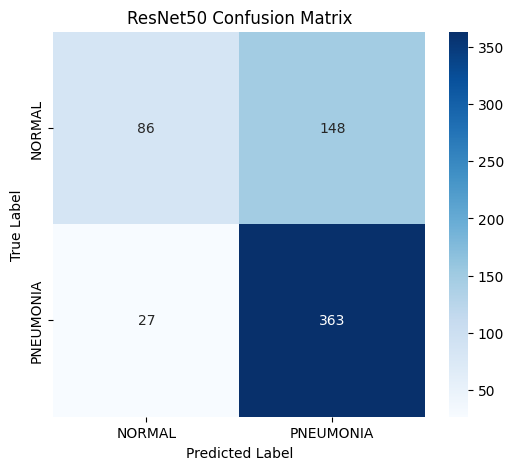

In [17]:
# ============================================================
# STEP 15: RESNET50 MODEL PERFORMANCE EVALUATION
# Purpose:
# Evaluate the trained ResNet50 transfer learning model
# on unseen test data using:
#
# 1. Accuracy
# 2. Precision
# 3. Recall
# 4. F1-score
# 5. Confusion Matrix
# ============================================================

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ============================================================
# GENERATE RESNET50 PREDICTIONS
# ============================================================

resnet_predictions = resnet_model.predict(test_generator)

# Convert predicted probabilities into binary class labels
resnet_predicted_classes = (resnet_predictions > 0.5).astype(int).reshape(-1)

# True labels
true_classes = test_generator.classes

# ============================================================
# CALCULATE TEST ACCURACY
# ============================================================

resnet_test_accuracy = accuracy_score(true_classes, resnet_predicted_classes)

print("ResNet50 Test Accuracy:", round(resnet_test_accuracy * 100, 2), "%")

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\nResNet50 Classification Report:\n")

print(classification_report(
    true_classes,
    resnet_predicted_classes,
    target_names=["NORMAL", "PNEUMONIA"]
))

# ============================================================
# CONFUSION MATRIX
# ============================================================

resnet_cm = confusion_matrix(true_classes, resnet_predicted_classes)

plt.figure(figsize=(6, 5))

sns.heatmap(
    resnet_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("ResNet50 Confusion Matrix")

plt.show()

In [18]:
# ============================================================
# STEP 18: MODEL PERFORMANCE COMPARISON TABLE
# Purpose:
# Compare CNN and ResNet50 model performance using test results.
# This supports Section 4.3 AI Model Performance Analysis.
# ============================================================

import pandas as pd

# Create model comparison table based on obtained test results
model_comparison = pd.DataFrame({
    "Model": ["CNN", "ResNet50"],
    "Accuracy (%)": [90.87, 72.60],
    "Precision": [0.91, 0.72],
    "Recall": [0.95, 0.91],
    "F1-Score": [0.93, 0.81]
})

# Display table
model_comparison

,Model,Accuracy (%),Precision,Recall,F1-Score
0,CNN,90.87,0.91,0.95,0.93
1,ResNet50,72.60,0.72,0.91,0.81


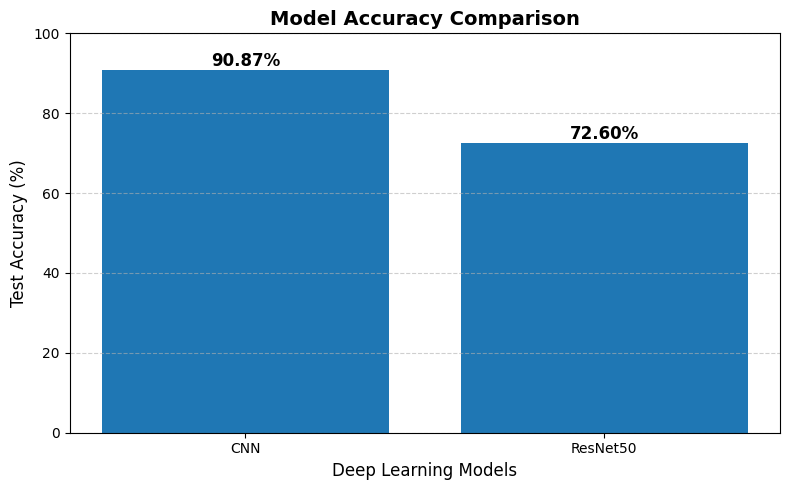

In [19]:
# ============================================================
# MODEL PERFORMANCE COMPARISON GRAPH
# Purpose:
# Generate a bar graph comparing CNN and ResNet50 test accuracy
# for AI-based pneumonia detection.
# ============================================================

import matplotlib.pyplot as plt

# Model names
models = ["CNN", "ResNet50"]

# Test accuracy values obtained from analysis
accuracy = [90.87, 72.60]

# Create figure
plt.figure(figsize=(8, 5))

# Create bar graph
bars = plt.bar(models, accuracy)

# Add accuracy values above bars
for bar, value in zip(bars, accuracy):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

# Graph title and labels
plt.title("Model Accuracy Comparison", fontsize=14, fontweight="bold")
plt.xlabel("Deep Learning Models", fontsize=12)
plt.ylabel("Test Accuracy (%)", fontsize=12)

# Set y-axis limit
plt.ylim(0, 100)

# Add grid
plt.grid(axis="y", linestyle="--", alpha=0.6)

# Improve layout
plt.tight_layout()

# Display graph
plt.show()

In [20]:
# ============================================================
# STEP 20: DISEASE DETECTION ANALYSIS TABLE
# Purpose:
# Analyze pneumonia and normal detection capability
# using CNN confusion matrix results.
# ============================================================

import pandas as pd

# CNN confusion matrix values
normal_correct = 197
normal_total = 234

pneumonia_correct = 370
pneumonia_total = 390

# Calculate detection accuracy
normal_detection_accuracy = (normal_correct / normal_total) * 100
pneumonia_detection_accuracy = (pneumonia_correct / pneumonia_total) * 100

# Create disease detection analysis table
disease_detection_table = pd.DataFrame({
    "Disease Category": ["NORMAL", "PNEUMONIA"],
    "Correct Predictions": [normal_correct, pneumonia_correct],
    "Total Cases": [normal_total, pneumonia_total],
    "Detection Accuracy (%)": [
        round(normal_detection_accuracy, 2),
        round(pneumonia_detection_accuracy, 2)
    ]
})

# Display table
disease_detection_table

,Disease Category,Correct Predictions,Total Cases,Detection Accuracy (%)
0,NORMAL,197,234,84.19
1,PNEUMONIA,370,390,94.87


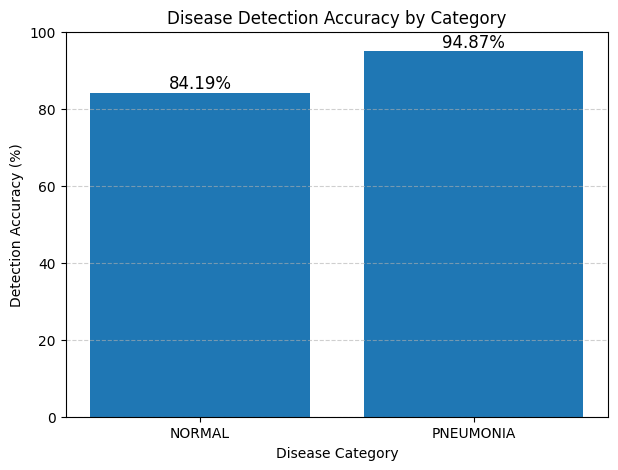

In [21]:
# ============================================================
# STEP 21: DISEASE DETECTION ACCURACY GRAPH
# Purpose:
# Visualize category-wise detection accuracy for NORMAL
# and PNEUMONIA classes using CNN results.
# ============================================================

import matplotlib.pyplot as plt

categories = ["NORMAL", "PNEUMONIA"]
detection_accuracies = [84.19, 94.87]

plt.figure(figsize=(7, 5))

bars = plt.bar(categories, detection_accuracies)

for bar, value in zip(bars, detection_accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center",
        fontsize=12
    )

plt.title("Disease Detection Accuracy by Category")
plt.xlabel("Disease Category")
plt.ylabel("Detection Accuracy (%)")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()

In [22]:
# ============================================================
# STEP 22: TECHNOLOGY COMPARISON ANALYSIS TABLE
# Purpose:
# Compare traditional medical imaging diagnosis with
# AI-assisted imaging systems.
# ============================================================

import pandas as pd

technology_comparison = pd.DataFrame({

    "Parameter": [
        "Diagnostic Speed",
        "Accuracy",
        "Human Dependency",
        "Automation",
        "Error Rate"
    ],

    "Traditional Imaging": [
        "Moderate",
        "Moderate",
        "High",
        "Limited",
        "Higher"
    ],

    "AI-Assisted Imaging": [
        "Fast",
        "High",
        "Reduced",
        "Extensive",
        "Lower"
    ]

})

# Display comparison table
technology_comparison

,Parameter,Traditional Imaging,AI-Assisted Imaging
0,Diagnostic Speed,Moderate,Fast
1,Accuracy,Moderate,High
2,Human Dependency,High,Reduced
3,Automation,Limited,Extensive
4,Error Rate,Higher,Lower


In [23]:
# ============================================================
# STEP 23: CLINICAL APPLICATION ANALYSIS TABLE
# Purpose:
# Summarize the clinical relevance of AI-assisted chest X-ray
# pneumonia detection.
# ============================================================

import pandas as pd

clinical_application_table = pd.DataFrame({

    "Clinical Aspect": [
        "Diagnostic Efficiency",
        "Early Disease Detection",
        "Clinical Decision Support",
        "Workflow Optimization",
        "Healthcare Accessibility"
    ],

    "Impact": [
        "Improved through faster automated image interpretation",
        "Enhanced by detecting pneumonia-related visual patterns",
        "Stronger support for radiologists and clinicians",
        "Better triage and reduced diagnostic workload",
        "Increased potential for screening in resource-limited settings"
    ]

})

clinical_application_table

,Clinical Aspect,Impact
0,Diagnostic Efficiency,Improved through faster automated image interp...
1,Early Disease Detection,Enhanced by detecting pneumonia-related visual...
2,Clinical Decision Support,Stronger support for radiologists and clinicians
3,Workflow Optimization,Better triage and reduced diagnostic workload
4,Healthcare Accessibility,Increased potential for screening in resource-...


In [24]:
# ============================================================
# STEP 24: FUTURE INTELLIGENT HEALTHCARE PERSPECTIVES
# Purpose:
# Summarize future directions linked with AI imaging,
# biosensing, smart hospitals, IoT, and personalized medicine.
# ============================================================

import pandas as pd

future_healthcare_table = pd.DataFrame({

    "Future Direction": [
        "AI-Enhanced Imaging",
        "Real-Time Healthcare Systems",
        "Wearable Biosensors",
        "Smart Hospitals",
        "IoT-Enabled Diagnostics",
        "Personalized Medicine"
    ],

    "Expected Contribution": [
        "Improves automated interpretation of radiological images",
        "Supports rapid screening and timely clinical response",
        "Enables continuous monitoring of physiological signals",
        "Integrates AI, imaging, sensors, and hospital workflows",
        "Connects diagnostic devices for remote and scalable healthcare",
        "Supports patient-specific diagnosis and treatment planning"
    ]

})

future_healthcare_table

,Future Direction,Expected Contribution
0,AI-Enhanced Imaging,Improves automated interpretation of radiologi...
1,Real-Time Healthcare Systems,Supports rapid screening and timely clinical r...
2,Wearable Biosensors,Enables continuous monitoring of physiological...
3,Smart Hospitals,"Integrates AI, imaging, sensors, and hospital ..."
4,IoT-Enabled Diagnostics,Connects diagnostic devices for remote and sca...
5,Personalized Medicine,Supports patient-specific diagnosis and treatm...


In [25]:
# ============================================================
# STEP 25: EXPORT RESULT TABLES
# Purpose:
# Save all analytical tables for manuscript writing and reporting.
# ============================================================

model_comparison.to_csv("model_performance_comparison.csv", index=False)
disease_detection_table.to_csv("disease_detection_analysis.csv", index=False)
technology_comparison.to_csv("technology_comparison_analysis.csv", index=False)
clinical_application_table.to_csv("clinical_application_analysis.csv", index=False)
future_healthcare_table.to_csv("future_intelligent_healthcare_perspectives.csv", index=False)

print("All result tables exported successfully.")
print("Files created:")
print("1. model_performance_comparison.csv")
print("2. disease_detection_analysis.csv")
print("3. technology_comparison_analysis.csv")
print("4. clinical_application_analysis.csv")
print("5. future_intelligent_healthcare_perspectives.csv")

All result tables exported successfully.
Files created:
1. model_performance_comparison.csv
2. disease_detection_analysis.csv
3. technology_comparison_analysis.csv
4. clinical_application_analysis.csv
5. future_intelligent_healthcare_perspectives.csv


CNN model called successfully.
Last Conv2D layer index: 9
Last Conv2D layer name: conv2d_3
Correct pneumonia samples found: 374
Correct normal samples found: 180
Selected pneumonia image: C:\Users\Ushas\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2\chest_xray\test\PNEUMONIA\person100_bacteria_475.jpeg
Selected normal image: C:\Users\Ushas\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2\chest_xray\test\NORMAL\IM-0001-0001.jpeg


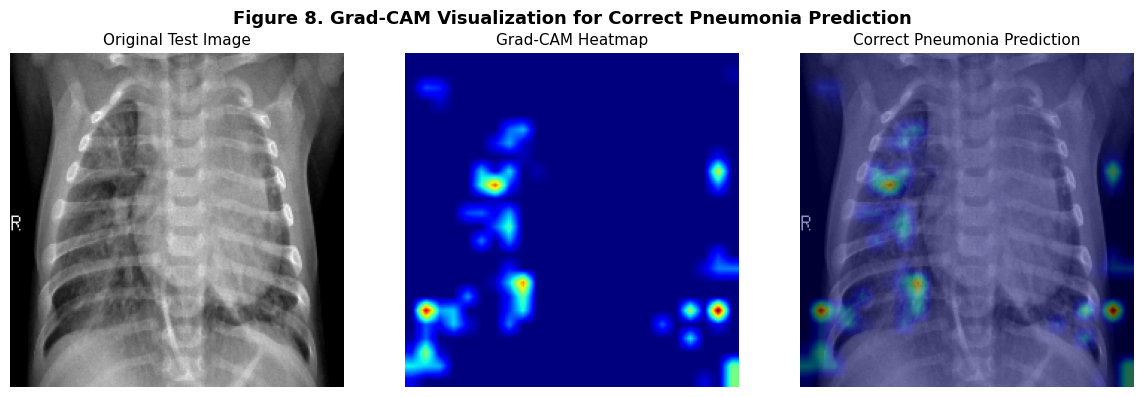

Saved: paper_figures\Figure_8_GradCAM_Correct_Pneumonia_CNN.png


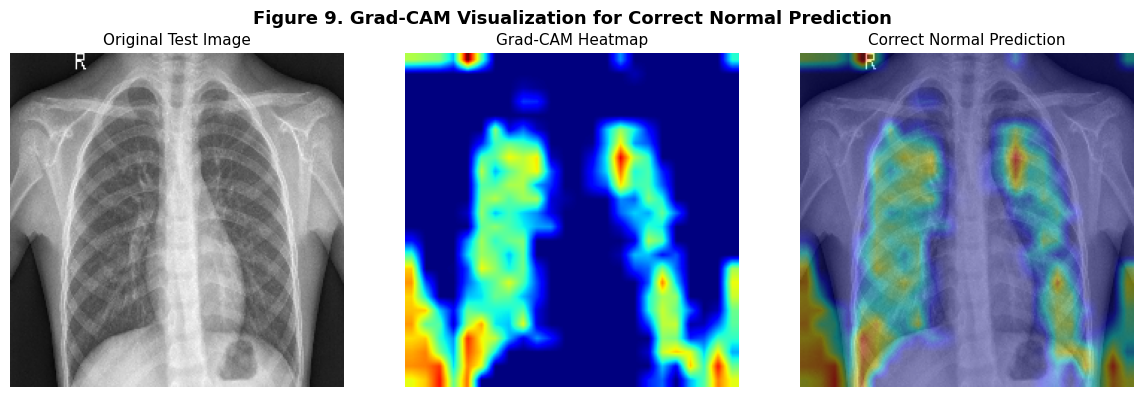

Saved: paper_figures\Figure_9_GradCAM_Correct_Normal_CNN.png

Grad-CAM figures generated successfully.
Figure 8 saved at: paper_figures\Figure_8_GradCAM_Correct_Pneumonia_CNN.png
Figure 9 saved at: paper_figures\Figure_9_GradCAM_Correct_Normal_CNN.png


In [28]:
# ============================================================
# FINAL FIXED GRAD-CAM CODE
# Works for Keras Sequential model without model.output / graph error
# Generates:
# Figure 8. Grad-CAM Visualization for Correct Pneumonia Prediction
# Figure 9. Grad-CAM Visualization for Correct Normal Prediction
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import cv2

from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.layers import Conv2D

OUTPUT_DIR = "paper_figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

IMAGE_SIZE = (224, 224)

# ------------------------------------------------------------
# 1. Build/call model once to avoid undefined output issues
# ------------------------------------------------------------

dummy_input = tf.zeros((1, 224, 224, 3))
_ = cnn_model(dummy_input, training=False)

print("CNN model called successfully.")

# ------------------------------------------------------------
# 2. Find last Conv2D layer index
# ------------------------------------------------------------

def find_last_conv_layer_index(model):
    last_conv_index = None
    last_conv_name = None

    for i, layer in enumerate(model.layers):
        if isinstance(layer, Conv2D):
            last_conv_index = i
            last_conv_name = layer.name

    if last_conv_index is None:
        print("Model layers:")
        for i, layer in enumerate(model.layers):
            print(i, layer.name, type(layer))
        raise ValueError("No Conv2D layer found in cnn_model.")

    return last_conv_index, last_conv_name


last_conv_index, last_conv_name = find_last_conv_layer_index(cnn_model)

print("Last Conv2D layer index:", last_conv_index)
print("Last Conv2D layer name:", last_conv_name)

# ------------------------------------------------------------
# 3. Read and preprocess single test image
# ------------------------------------------------------------

def preprocess_single_image(image_path, image_size=(224, 224)):
    img = load_img(image_path, target_size=image_size)
    img_array = img_to_array(img)
    img_array = img_array / 255.0
    img_batch = np.expand_dims(img_array, axis=0).astype("float32")
    return img_array, img_batch

# ------------------------------------------------------------
# 4. Grad-CAM without using model.output or model.get_layer().output
# ------------------------------------------------------------

def make_gradcam_heatmap_sequential(img_batch, model, last_conv_index):
    """
    Generates Grad-CAM heatmap by manually passing image through each layer.
    This avoids Keras graph connection errors.
    """

    img_tensor = tf.convert_to_tensor(img_batch)

    with tf.GradientTape() as tape:
        x = img_tensor
        conv_outputs = None

        for i, layer in enumerate(model.layers):
            try:
                x = layer(x, training=False)
            except TypeError:
                x = layer(x)

            if i == last_conv_index:
                conv_outputs = x
                tape.watch(conv_outputs)

        predictions = x

        # Binary classification output
        if len(predictions.shape) == 2 and predictions.shape[-1] == 1:
            class_score = predictions[:, 0]
        else:
            class_index = tf.argmax(predictions[0])
            class_score = predictions[:, class_index]

    grads = tape.gradient(class_score, conv_outputs)

    if grads is None:
        raise ValueError(
            "Gradients are None. Check whether the selected Conv2D layer is connected to final output."
        )

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0)

    max_value = tf.reduce_max(heatmap)
    heatmap = heatmap / (max_value + tf.keras.backend.epsilon())

    return heatmap.numpy()

# ------------------------------------------------------------
# 5. Save Grad-CAM figure
# ------------------------------------------------------------

def save_gradcam_figure(
    image_path,
    model,
    prediction_label,
    output_path,
    figure_title,
    image_size=(224, 224)
):
    img_array, img_batch = preprocess_single_image(
        image_path=image_path,
        image_size=image_size
    )

    heatmap = make_gradcam_heatmap_sequential(
        img_batch=img_batch,
        model=model,
        last_conv_index=last_conv_index
    )

    heatmap_resized = cv2.resize(heatmap, image_size)

    heatmap_uint8 = np.uint8(255 * heatmap_resized)
    heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)

    original_uint8 = np.uint8(255 * img_array)

    superimposed_img = cv2.addWeighted(
        original_uint8,
        0.60,
        heatmap_color,
        0.40,
        0
    )

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(original_uint8)
    plt.title("Original Test Image", fontsize=11)
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title("Grad-CAM Heatmap", fontsize=11)
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(superimposed_img)
    plt.title(prediction_label, fontsize=11)
    plt.axis("off")

    plt.suptitle(figure_title, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", output_path)

# ------------------------------------------------------------
# 6. Select correct pneumonia and correct normal test images
# ------------------------------------------------------------

normal_class_index = class_indices.get("NORMAL", 0)
pneumonia_class_index = class_indices.get("PNEUMONIA", 1)

correct_pneumonia_indices = np.where(
    (true_labels == pneumonia_class_index) &
    (cnn_preds == pneumonia_class_index)
)[0]

correct_normal_indices = np.where(
    (true_labels == normal_class_index) &
    (cnn_preds == normal_class_index)
)[0]

print("Correct pneumonia samples found:", len(correct_pneumonia_indices))
print("Correct normal samples found:", len(correct_normal_indices))

if len(correct_pneumonia_indices) == 0:
    raise ValueError("No correctly predicted pneumonia image found.")

if len(correct_normal_indices) == 0:
    raise ValueError("No correctly predicted normal image found.")

pneumonia_img_path = file_paths[correct_pneumonia_indices[0]]
normal_img_path = file_paths[correct_normal_indices[0]]

print("Selected pneumonia image:", pneumonia_img_path)
print("Selected normal image:", normal_img_path)

# ------------------------------------------------------------
# 7. Figure 8: Correct Pneumonia Grad-CAM
# ------------------------------------------------------------

fig8_path = os.path.join(
    OUTPUT_DIR,
    "Figure_8_GradCAM_Correct_Pneumonia_CNN.png"
)

save_gradcam_figure(
    image_path=pneumonia_img_path,
    model=cnn_model,
    prediction_label="Correct Pneumonia Prediction",
    output_path=fig8_path,
    figure_title="Figure 8. Grad-CAM Visualization for Correct Pneumonia Prediction"
)

# ------------------------------------------------------------
# 8. Figure 9: Correct Normal Grad-CAM
# ------------------------------------------------------------

fig9_path = os.path.join(
    OUTPUT_DIR,
    "Figure_9_GradCAM_Correct_Normal_CNN.png"
)

save_gradcam_figure(
    image_path=normal_img_path,
    model=cnn_model,
    prediction_label="Correct Normal Prediction",
    output_path=fig9_path,
    figure_title="Figure 9. Grad-CAM Visualization for Correct Normal Prediction"
)

print("\nGrad-CAM figures generated successfully.")
print("Figure 8 saved at:", fig8_path)
print("Figure 9 saved at:", fig9_path)

Using existing dataset_dir: C:\Users\Ushas\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2\chest_xray
Test directory: C:\Users\Ushas\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2\chest_xray\test
Using CNN model from notebook memory.
Using ResNet50 model from notebook memory.
Found 624 images belonging to 2 classes.
Class indices: {'NORMAL': 0, 'PNEUMONIA': 1}
Total test images: 624
Normal images: 234
Pneumonia images: 390
20/20 ━━━━━━━━━━━━━━━━━━━━ 17s 629ms/step
CNN probability range: 0.0000 to 1.0000
20/20 ━━━━━━━━━━━━━━━━━━━━ 43s 2s/step
ResNet50 probability range: 0.1320 to 0.9366


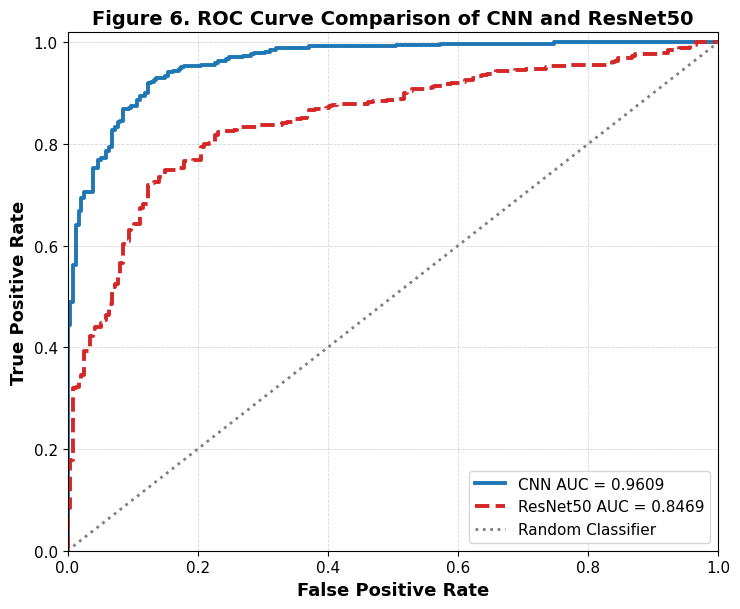

Saved Figure 6: paper_figures_colored\Figure_6_ROC_Curve_Comparison_CNN_vs_ResNet50_Colored.png


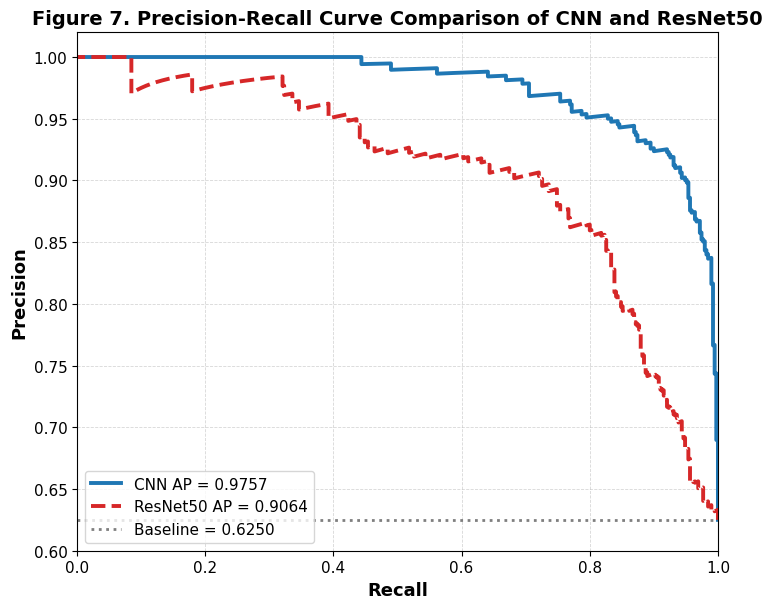

Saved Figure 7: paper_figures_colored\Figure_7_Precision_Recall_Curve_Comparison_CNN_vs_ResNet50_Colored.png

Colored ROC and Precision-Recall figures generated successfully.
Figure 6 saved at: paper_figures_colored\Figure_6_ROC_Curve_Comparison_CNN_vs_ResNet50_Colored.png
Figure 7 saved at: paper_figures_colored\Figure_7_Precision_Recall_Curve_Comparison_CNN_vs_ResNet50_Colored.png

Metric Summary:
CNN ROC-AUC: 0.9609
ResNet50 ROC-AUC: 0.8469
CNN Average Precision: 0.9757
ResNet50 Average Precision: 0.9064
PR Baseline: 0.6250


In [31]:
# ============================================================
# FINAL COLORED CODE
# Figure 6: ROC Curve Comparison of CNN and ResNet50
# Figure 7: Precision-Recall Curve Comparison of CNN and ResNet50
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

# ============================================================
# 1. Reproducibility
# ============================================================

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ============================================================
# 2. Output Folder
# ============================================================

OUTPUT_DIR = "paper_figures_colored"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================
# 3. Dataset Path
# ============================================================

try:
    dataset_dir
    print("Using existing dataset_dir:", dataset_dir)
except NameError:
    import kagglehub
    dataset_path = kagglehub.dataset_download(
        "paultimothymooney/chest-xray-pneumonia"
    )
    dataset_dir = os.path.join(dataset_path, "chest_xray")
    print("Dataset loaded from:", dataset_dir)

test_dir = os.path.join(dataset_dir, "test")
print("Test directory:", test_dir)

# ============================================================
# 4. Load Models
# ============================================================

try:
    cnn_model
    print("Using CNN model from notebook memory.")
except NameError:
    cnn_model = load_model("best_cnn_model.keras")
    print("Loaded CNN model from best_cnn_model.keras")

try:
    resnet_model
    print("Using ResNet50 model from notebook memory.")
except NameError:
    resnet_model = load_model("best_resnet50_model.keras")
    print("Loaded ResNet50 model from best_resnet50_model.keras")

# ============================================================
# 5. Test Data Generator
# ============================================================

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

test_datagen = ImageDataGenerator(rescale=1.0 / 255.0)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

print("Class indices:", test_generator.class_indices)

pneumonia_index = test_generator.class_indices["PNEUMONIA"]
y_true = (test_generator.classes == pneumonia_index).astype(int)

print("Total test images:", len(y_true))
print("Normal images:", np.sum(y_true == 0))
print("Pneumonia images:", np.sum(y_true == 1))

# ============================================================
# 6. Prediction Function
# ============================================================

def get_pneumonia_probability(model, generator, model_name):
    generator.reset()
    preds = model.predict(generator, verbose=1)
    preds = np.asarray(preds)

    # Binary sigmoid output
    if preds.ndim == 2 and preds.shape[1] == 1:
        probs = preds[:, 0]

    # Two-class softmax output
    elif preds.ndim == 2 and preds.shape[1] == 2:
        probs = preds[:, pneumonia_index]

    # Flat output
    elif preds.ndim == 1:
        probs = preds

    else:
        raise ValueError(f"{model_name} prediction shape not supported: {preds.shape}")

    probs = probs.astype(float)
    probs = np.clip(probs, 0, 1)

    print(f"{model_name} probability range: {probs.min():.4f} to {probs.max():.4f}")

    return probs

cnn_probs = get_pneumonia_probability(cnn_model, test_generator, "CNN")
resnet_probs = get_pneumonia_probability(resnet_model, test_generator, "ResNet50")

# ============================================================
# 7. Figure 6: Colored ROC Curve
# ============================================================

cnn_fpr, cnn_tpr, _ = roc_curve(y_true, cnn_probs)
resnet_fpr, resnet_tpr, _ = roc_curve(y_true, resnet_probs)

cnn_auc = auc(cnn_fpr, cnn_tpr)
resnet_auc = auc(resnet_fpr, resnet_tpr)

plt.figure(figsize=(7.5, 6.2))

plt.plot(
    cnn_fpr,
    cnn_tpr,
    color="#1f77b4",
    linewidth=2.8,
    label=f"CNN AUC = {cnn_auc:.4f}"
)

plt.plot(
    resnet_fpr,
    resnet_tpr,
    color="#d62728",
    linestyle="--",
    linewidth=2.8,
    label=f"ResNet50 AUC = {resnet_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    color="#7f7f7f",
    linestyle=":",
    linewidth=2,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate", fontsize=13, fontweight="bold")
plt.ylabel("True Positive Rate", fontsize=13, fontweight="bold")
plt.title(
    "Figure 6. ROC Curve Comparison of CNN and ResNet50",
    fontsize=14,
    fontweight="bold"
)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.02])

plt.legend(loc="lower right", fontsize=11, frameon=True)
plt.grid(True, linestyle="--", linewidth=0.6, alpha=0.5)
plt.tight_layout()

roc_path = os.path.join(
    OUTPUT_DIR,
    "Figure_6_ROC_Curve_Comparison_CNN_vs_ResNet50_Colored.png"
)

plt.savefig(roc_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved Figure 6:", roc_path)

# ============================================================
# 8. Figure 7: Colored Precision-Recall Curve
# ============================================================

cnn_precision, cnn_recall, _ = precision_recall_curve(y_true, cnn_probs)
resnet_precision, resnet_recall, _ = precision_recall_curve(y_true, resnet_probs)

cnn_ap = average_precision_score(y_true, cnn_probs)
resnet_ap = average_precision_score(y_true, resnet_probs)

baseline_precision = np.mean(y_true)

plt.figure(figsize=(7.5, 6.2))

plt.plot(
    cnn_recall,
    cnn_precision,
    color="#1f77b4",
    linewidth=2.8,
    label=f"CNN AP = {cnn_ap:.4f}"
)

plt.plot(
    resnet_recall,
    resnet_precision,
    color="#d62728",
    linestyle="--",
    linewidth=2.8,
    label=f"ResNet50 AP = {resnet_ap:.4f}"
)

plt.axhline(
    y=baseline_precision,
    color="#7f7f7f",
    linestyle=":",
    linewidth=2,
    label=f"Baseline = {baseline_precision:.4f}"
)

plt.xlabel("Recall", fontsize=13, fontweight="bold")
plt.ylabel("Precision", fontsize=13, fontweight="bold")
plt.title(
    "Figure 7. Precision-Recall Curve Comparison of CNN and ResNet50",
    fontsize=14,
    fontweight="bold"
)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.xlim([0.0, 1.0])
plt.ylim([0.60, 1.02])

plt.legend(loc="lower left", fontsize=11, frameon=True)
plt.grid(True, linestyle="--", linewidth=0.6, alpha=0.5)
plt.tight_layout()

pr_path = os.path.join(
    OUTPUT_DIR,
    "Figure_7_Precision_Recall_Curve_Comparison_CNN_vs_ResNet50_Colored.png"
)

plt.savefig(pr_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved Figure 7:", pr_path)

# ============================================================
# 9. Final Summary
# ============================================================

print("\nColored ROC and Precision-Recall figures generated successfully.")
print("Figure 6 saved at:", roc_path)
print("Figure 7 saved at:", pr_path)

print("\nMetric Summary:")
print(f"CNN ROC-AUC: {cnn_auc:.4f}")
print(f"ResNet50 ROC-AUC: {resnet_auc:.4f}")
print(f"CNN Average Precision: {cnn_ap:.4f}")
print(f"ResNet50 Average Precision: {resnet_ap:.4f}")
print(f"PR Baseline: {baseline_precision:.4f}")